In [2]:
import pandas as pd

train_df = pd.read_csv("/content/datatraining.txt", index_col=0)

print("Rows and columns:", train_df.shape)
display(train_df.head())


Rows and columns: (8143, 7)


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [3]:
print("COLUMN TYPES")
print(train_df.dtypes)

print("\nMISSING VALUES")
print(train_df.isna().sum())

print("\nDUPLICATE ROWS")
print(train_df.duplicated().sum())

print("\nOCCUPANCY COUNTS")
print(train_df["Occupancy"].value_counts().sort_index())

COLUMN TYPES
date              object
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

MISSING VALUES
date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

DUPLICATE ROWS
0

OCCUPANCY COUNTS
Occupancy
0    6414
1    1729
Name: count, dtype: int64


In [4]:
train_df["date"] = pd.to_datetime(
    train_df["date"], errors="raise"
)

train_df = train_df.sort_values("date")

print("Earliest observation:", train_df["date"].min())
print("Latest observation:", train_df["date"].max())
print("Repeated timestamps:", train_df["date"].duplicated().sum())

Earliest observation: 2015-02-04 17:51:00
Latest observation: 2015-02-10 09:33:00
Repeated timestamps: 0


In [5]:
test1_df = pd.read_csv("/content/datatest.txt", index_col=0)
test2_df = pd.read_csv("/content/datatest2.txt", index_col=0)

for name, data in [
    ("Training", train_df),
    ("Test 1", test1_df),
    ("Test 2", test2_df)
]:
    data["date"] = pd.to_datetime(data["date"], errors="raise")

    print(f"\n{name}: {len(data):,} rows")
    print("Start:")
    print(data["date"].min())
    print("End:")
    print(data["date"].max())


Training: 8,143 rows
Start:
2015-02-04 17:51:00
End:
2015-02-10 09:33:00

Test 1: 2,665 rows
Start:
2015-02-02 14:19:00
End:
2015-02-04 10:43:00

Test 2: 9,752 rows
Start:
2015-02-11 14:48:00
End:
2015-02-18 09:19:00


## Project aim and research questions

My project compares Logistic Regression and Random Forest for
detecting whether an office room is being used with environmental
sensor measurements.

Target audience: a technical manager assessing the occupancy detection
for potential building-management applications.

Research questions:
1. How do sensor measurements differ between occupied and empty times?
2. Which model identifies occupied periods better, measured using
   precision, recall and F1-score?
3. How well do the models generalise to a later recording period?

The training set is used for exploration and model development.
Validation will preserve chronological order. Both supplied test sets
are reserved for evaluation, with Test 2 providing the later-period test.## Project aim and research questions.

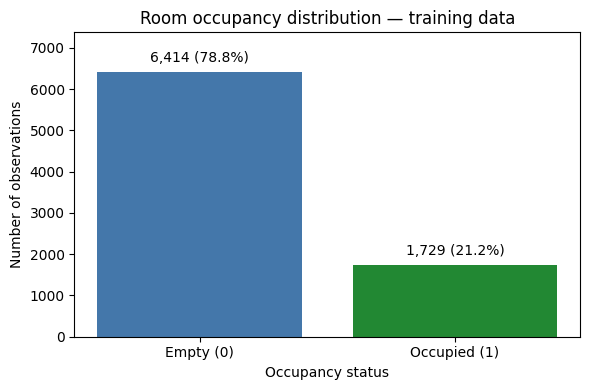

In [6]:
import matplotlib.pyplot as plt

counts = train_df["Occupancy"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Empty (0)", "Occupied (1)"],
    counts.values,
    color=["#4477AA", "#228833"]
)

labels = [
    f"{count:,} ({count / len(train_df):.1%})"
    for count in counts.values
]
ax.bar_label(bars, labels=labels, padding=5)

ax.set_title("Room occupancy distribution — training data")
ax.set_xlabel("Occupancy status")
ax.set_ylabel("Number of observations")
ax.set_ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.savefig("training_occupancy_distribution.png", dpi=300)
plt.show()

The training set has 6,414 empty observations (78.8%) and 1,729 occupied observations (21.2%). This imbalance means accuracy alone could be misleading: predicting every observation as empty would get 78.8% training accuracy. Precision, recall and F1-score will therefore be used to assess detection of occupied periods.

,Temperature,Humidity,Light,CO2,HumidityRatio
count,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000
mean,20.619084,25.731507,119.519375,606.546243,0.003863
std,1.016916,5.531211,194.755805,314.320877,0.000852
min,19.000000,16.745000,0.000000,412.750000,0.002674
25%,19.700000,20.200000,0.000000,439.000000,0.003078
50%,20.390000,26.222500,0.000000,453.500000,0.003801
75%,21.390000,30.533333,256.375000,638.833333,0.004352
max,23.180000,39.117500,1546.333333,2028.500000,0.006476


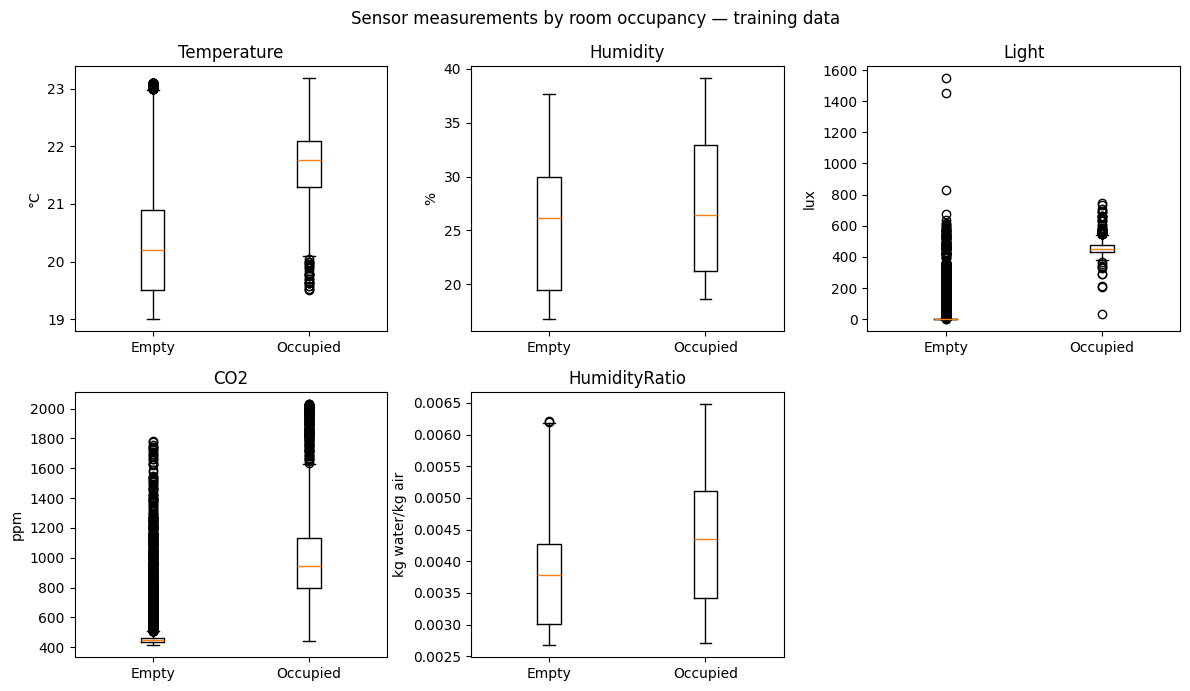

In [7]:
sensor_columns = [
    "Temperature", "Humidity", "Light", "CO2", "HumidityRatio"
]

display(train_df[sensor_columns].describe())

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

units = ["°C", "%", "lux", "ppm", "kg water/kg air"]

for ax, column, unit in zip(axes.flat, sensor_columns, units):
    groups = [
        train_df.loc[train_df["Occupancy"] == status, column]
        for status in [0, 1]
    ]

    ax.boxplot(groups)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Empty", "Occupied"])
    ax.set_title(column)
    ax.set_ylabel(unit)

axes.flat[-1].axis("off")
fig.suptitle("Sensor measurements by room occupancy — training data")
plt.tight_layout()
plt.savefig("training_sensor_boxplots.png", dpi=300)
plt.show()

The boxplots shows that light, CO₂ and temperature helps seperate occupied from empty periods. Relative humidity shows a big overlap between classes, while humidity ratio shows a smaller difference in medians. These patterns show associations rather than causation and do not establish model feature importance. Extreme observations are retained because the boxplots alone do not demonstrate measurement errors.

In [8]:
median_by_class = (
    train_df.groupby("Occupancy")[sensor_columns]
    .median()
    .rename(index={0: "Empty", 1: "Occupied"})
)

display(median_by_class.round(4).T)

Occupancy,Empty,Occupied
Temperature,20.2000,21.7675
Humidity,26.1875,26.4425
Light,0.0000,454.0000
CO2,446.0000,944.0000
HumidityRatio,0.0038,0.0043


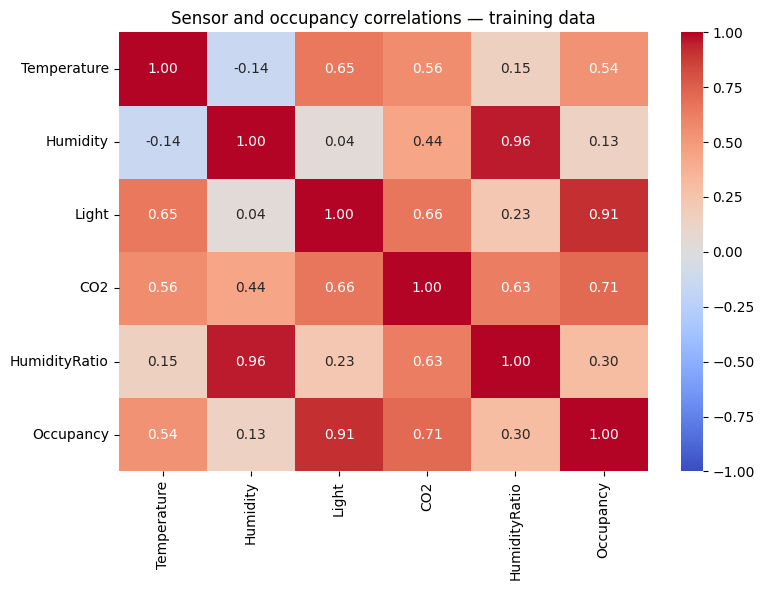

In [9]:
import seaborn as sns

correlations = train_df[sensor_columns + ["Occupancy"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Sensor and occupancy correlations — training data")
plt.tight_layout()
plt.savefig("training_correlations.png", dpi=300)
plt.show()

Light and CO₂ show strong positive associations with occupancy in the training data. Humidity and humidity ratio are highly correlated, demonstrating redundant information. All five sensors will be kept; removing humidity ratio can later be investigated using training-only validation. Correlation alone doesnt establish predictive performance.

In [10]:
X_train = train_df[sensor_columns].copy()
y_train = train_df["Occupancy"].copy()

print("Input data shape:", X_train.shape)
print("Target shape:", y_train.shape)
print("Predictors:", X_train.columns.tolist())
print("Target classes:", sorted(y_train.unique()))

Input data shape: (8143, 5)
Target shape: (8143,)
Predictors: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
Target classes: [np.int64(0), np.int64(1)]


In [11]:
from sklearn.model_selection import TimeSeriesSplit

time_cv = TimeSeriesSplit(n_splits=3, gap=60)

for fold, (fit_idx, val_idx) in enumerate(
    time_cv.split(X_train), start=1
):
    print(f"\nROUND {fold}")
    print("Training rows:", len(fit_idx))
    print("Validation rows:", len(val_idx))

    print("Training class counts:")
    print(y_train.iloc[fit_idx].value_counts().sort_index())

    print("Validation class counts:")
    print(y_train.iloc[val_idx].value_counts().sort_index())


ROUND 1
Training rows: 1978
Validation rows: 2035
Training class counts:
Occupancy
0    1423
1     555
Name: count, dtype: int64
Validation class counts:
Occupancy
0    1449
1     586
Name: count, dtype: int64

ROUND 2
Training rows: 4013
Validation rows: 2035
Training class counts:
Occupancy
0    2872
1    1141
Name: count, dtype: int64
Validation class counts:
Occupancy
0    2035
Name: count, dtype: int64

ROUND 3
Training rows: 6048
Validation rows: 2035
Training class counts:
Occupancy
0    4907
1    1141
Name: count, dtype: int64
Validation class counts:
Occupancy
0    1447
1     588
Name: count, dtype: int64


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- Baseline
- Logistic Regression
- Random Forest


In [13]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

fold_results = []
pooled_results = []

for name, model in models.items():
    actual_all = []
    predicted_all = []

    for fold, (fit_idx, val_idx) in enumerate(
        time_cv.split(X_train), start=1
    ):
        fitted = clone(model)
        fitted.fit(
            X_train.iloc[fit_idx],
            y_train.iloc[fit_idx]
        )

        actual = y_train.iloc[val_idx]
        predicted = fitted.predict(X_train.iloc[val_idx])

        tn, fp, fn, tp = confusion_matrix(
            actual, predicted, labels=[0, 1]
        ).ravel()

        fold_results.append({
            "Model": name,
            "Round": fold,
            "Accuracy": accuracy_score(actual, predicted),
            "Occupied observations": int((actual == 1).sum()),
            "False alarms": int(fp),
            "Missed occupied": int(fn)
        })

        actual_all.extend(actual.tolist())
        predicted_all.extend(predicted.tolist())

    pooled_results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual_all, predicted_all),
        "Precision": precision_score(
            actual_all, predicted_all, zero_division=0
        ),
        "Recall": recall_score(
            actual_all, predicted_all, zero_division=0
        ),
        "F1": f1_score(
            actual_all, predicted_all, zero_division=0
        )
    })

fold_results_df = pd.DataFrame(fold_results)
cv_results_df = pd.DataFrame(pooled_results).set_index("Model")

print("RESULTS BY ROUND")
display(fold_results_df.round(4))

print("COMBINED VALIDATION RESULTS")
display(cv_results_df.round(4))

RESULTS BY ROUND


,Model,Round,Accuracy,Occupied observations,False alarms,Missed occupied
0,Baseline,1,0.7120,586,0,586
1,Baseline,2,1.0000,0,0,0
2,Baseline,3,0.7111,588,0,588
3,Logistic Regression,1,0.9887,586,21,2
4,Logistic Regression,2,0.9995,0,1,0
5,Logistic Regression,3,0.9636,588,30,44
6,Random Forest,1,0.8722,586,256,4
7,Random Forest,2,1.0000,0,0,0
8,Random Forest,3,0.9956,588,5,4


COMBINED VALIDATION RESULTS


,Accuracy,Precision,Recall,F1
Model,,,,
Baseline,0.8077,0.0000,0.0000,0.0000
Logistic Regression,0.9839,0.9559,0.9608,0.9584
Random Forest,0.9559,0.8171,0.9932,0.8966



Across the chronological validation predictions, Logistic Regression got the highest F1-score (0.9584), compared with Random Forest (0.8966). Random Forest achieved higher recall but lower precision, demonstrating fewer missed occupied observations and more false alarms. The baseline achieved 80.77% accuracy while detecting no occupied observations, demonstrating why accuracy alone is not enough. These results are preliminary and both external test sets remain reserved for final evaluation.

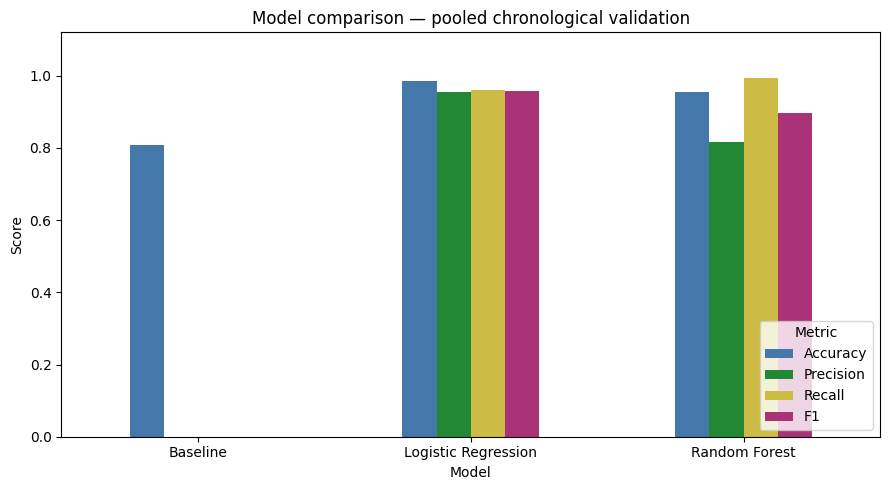

In [14]:
ax = cv_results_df.plot.bar(
    figsize=(9, 5),
    ylim=(0, 1.12),
    rot=0,
    color=["#4477AA", "#228833", "#CCBB44", "#AA3377"]
)

ax.set_title("Model comparison — pooled chronological validation")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.legend(title="Metric", loc="lower right")

plt.tight_layout()
plt.savefig("validation_model_comparison.png", dpi=300)
plt.show()

cv_results_df.to_csv("validation_summary.csv")
fold_results_df.to_csv("validation_by_round.csv", index=False)

In [15]:
experiments = [
    ("LR: C=0.1", "Logistic Regression",
     {"logisticregression__C": 0.1}, sensor_columns),

    ("LR: C=10", "Logistic Regression",
     {"logisticregression__C": 10}, sensor_columns),

    ("LR: no humidity ratio", "Logistic Regression",
     {}, [c for c in sensor_columns if c != "HumidityRatio"]),

    ("RF: depth=5, leaf=5", "Random Forest",
     {"max_depth": 5, "min_samples_leaf": 5}, sensor_columns),

    ("RF: depth=10, leaf=5", "Random Forest",
     {"max_depth": 10, "min_samples_leaf": 5}, sensor_columns)
]

experiment_results = []

for label, model_name, settings, columns in experiments:
    actual_all = []
    predicted_all = []

    for fit_idx, val_idx in time_cv.split(X_train):
        candidate = clone(models[model_name]).set_params(**settings)

        candidate.fit(
            X_train.iloc[fit_idx][columns],
            y_train.iloc[fit_idx]
        )

        predictions = candidate.predict(
            X_train.iloc[val_idx][columns]
        )

        actual_all.extend(y_train.iloc[val_idx].tolist())
        predicted_all.extend(predictions.tolist())

    experiment_results.append({
        "Experiment": label,
        "Accuracy": accuracy_score(actual_all, predicted_all),
        "Precision": precision_score(
            actual_all, predicted_all, zero_division=0
        ),
        "Recall": recall_score(
            actual_all, predicted_all, zero_division=0
        ),
        "F1": f1_score(
            actual_all, predicted_all, zero_division=0
        )
    })

tuning_results_df = pd.DataFrame(
    experiment_results
).set_index("Experiment")

display(tuning_results_df.sort_values("F1", ascending=False).round(4))
tuning_results_df.to_csv("tuning_validation_results.csv")

,Accuracy,Precision,Recall,F1
Experiment,,,,
LR: no humidity ratio,0.9844,0.9576,0.9617,0.9596
LR: C=0.1,0.9833,0.9519,0.9617,0.9568
LR: C=10,0.9817,0.9425,0.9634,0.9528
"RF: depth=5, leaf=5",0.9602,0.8299,0.9974,0.9060
"RF: depth=10, leaf=5",0.9594,0.8270,0.9974,0.9042


Removing humidity ratio slightly increased Logistic Regression’s pooled validation F1 from 0.9584 to 0.9596. Restricting Random Forest to a maximum depth of five and a minimum leaf size of five improved its F1 from 0.8966 to 0.9060. Logistic Regression without humidity ratio was chosen as the preferred model before evaluating either test set. These validation scores were used for selection and are not independent final performance estimates.

In [16]:
lr_columns = [
    c for c in sensor_columns if c != "HumidityRatio"
]

final_models = {
    "Baseline": (
        clone(models["Baseline"]),
        sensor_columns
    ),
    "Logistic Regression": (
        clone(models["Logistic Regression"]),
        lr_columns
    ),
    "Random Forest": (
        clone(models["Random Forest"]).set_params(
            max_depth=5,
            min_samples_leaf=5
        ),
        sensor_columns
    )
}

training_results = []

for name, (model, columns) in final_models.items():
    model.fit(X_train[columns], y_train)
    predictions = model.predict(X_train[columns])

    training_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

training_results_df = pd.DataFrame(
    training_results
).set_index("Model")

display(training_results_df.round(4))
training_results_df.to_csv("training_results.csv")

,Accuracy,Precision,Recall,F1
Model,,,,
Baseline,0.7877,0.0000,0.0000,0.0000
Logistic Regression,0.9860,0.9494,0.9867,0.9677
Random Forest,0.9904,0.9604,0.9960,0.9779


In [17]:
test_results = []
test_predictions = {}

for dataset_name, data in [
    ("Test 1 — earlier period", test1_df),
    ("Test 2 — later period", test2_df)
]:
    assert data[sensor_columns + ["Occupancy"]].notna().all().all()
    assert data["Occupancy"].isin([0, 1]).all()

    actual = data["Occupancy"]

    for model_name, (model, columns) in final_models.items():
        predicted = model.predict(data[columns])

        test_predictions[(dataset_name, model_name)] = predicted

        tn, fp, fn, tp = confusion_matrix(
            actual, predicted, labels=[0, 1]
        ).ravel()

        test_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(actual, predicted),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1": f1_score(
                actual, predicted, zero_division=0
            ),
            "False alarms": int(fp),
            "Missed occupied": int(fn)
        })

test_results_df = pd.DataFrame(test_results)

for dataset_name in test_results_df["Dataset"].unique():
    print("\n" + dataset_name)
    display(
        test_results_df[
            test_results_df["Dataset"] == dataset_name
        ].drop(columns="Dataset").set_index("Model").round(4)
    )

test_results_df.to_csv("final_test_results.csv", index=False)


Test 1 — earlier period


,Accuracy,Precision,Recall,F1,False alarms,Missed occupied
Model,,,,,,
Baseline,0.6353,0.0000,0.0000,0.0000,0,972
Logistic Regression,0.9779,0.9471,0.9949,0.9704,54,5
Random Forest,0.9614,0.9466,0.9475,0.9470,52,51



Test 2 — later period


,Accuracy,Precision,Recall,F1,False alarms,Missed occupied
Model,,,,,,
Baseline,0.7899,0.0000,0.0000,0.0000,0,2049
Logistic Regression,0.9867,0.9743,0.9619,0.9681,52,78
Random Forest,0.9880,0.9721,0.9707,0.9714,57,60


Logistic Regression achieved higher F1 on the earlier test period (0.9704 versus 0.9470), while Random Forest achieved slightly higher F1 on the later period (0.9714 versus 0.9681). On Test 2, Logistic Regression produced 52 false alarms and missed 78 occupied observations; Random Forest produced 57 false alarms and missed 60. Neither model was consistently better than the other across both periods. Logistic Regression remained the model selected through training-only validation. These results concern one room over a limited recording period and do not establish performance in other buildings.

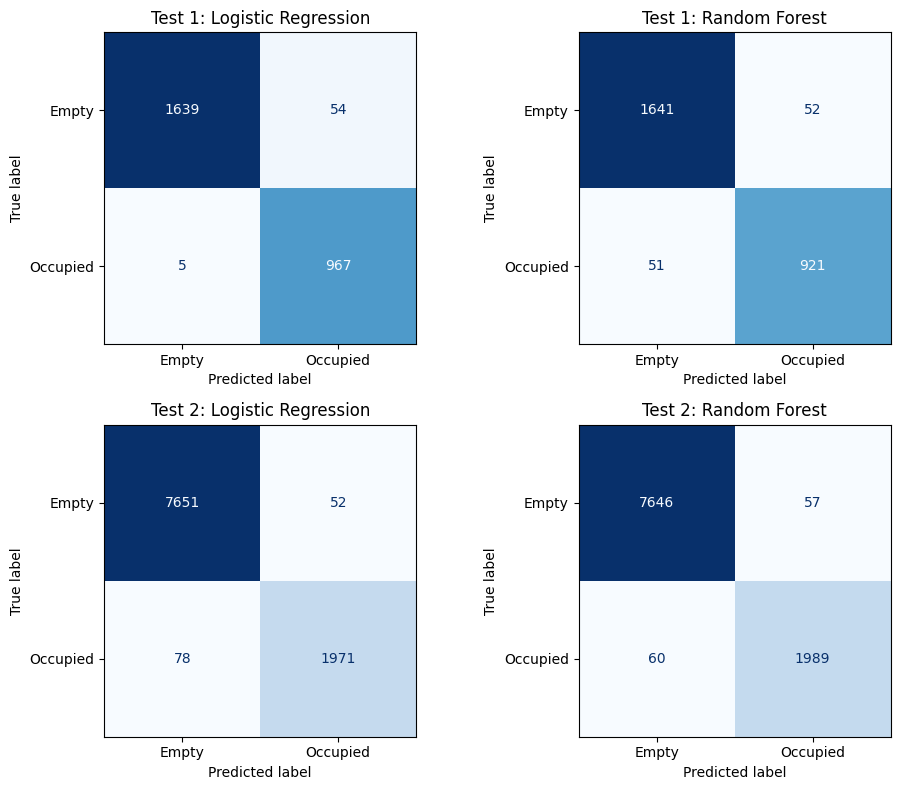

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

datasets = [
    ("Test 1 — earlier period", test1_df),
    ("Test 2 — later period", test2_df)
]
model_names = ["Logistic Regression", "Random Forest"]

for row, (dataset_name, data) in enumerate(datasets):
    for col, model_name in enumerate(model_names):
        predicted = test_predictions[(dataset_name, model_name)]

        ConfusionMatrixDisplay.from_predictions(
            data["Occupancy"],
            predicted,
            labels=[0, 1],
            display_labels=["Empty", "Occupied"],
            cmap="Blues",
            colorbar=False,
            ax=axes[row, col]
        )

        axes[row, col].set_title(
            f"Test {row + 1}: {model_name}"
        )

plt.tight_layout()
plt.savefig("test_confusion_matrices.png", dpi=300)
plt.show()

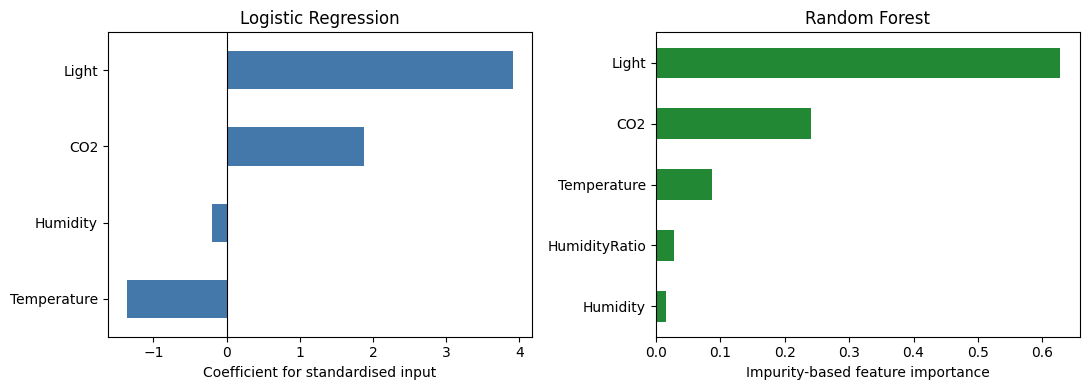

Logistic Regression coefficients


,0
Temperature,-1.359881
Humidity,-0.197517
CO2,1.878859
Light,3.912019


Random Forest feature importance


,0
Humidity,0.015805
HumidityRatio,0.028069
Temperature,0.087471
CO2,0.241666
Light,0.626990


In [19]:
lr_model = final_models["Logistic Regression"][0]

coefficients = pd.Series(
    lr_model.named_steps["logisticregression"].coef_[0],
    index=lr_columns
).sort_values()

rf_model = final_models["Random Forest"][0]

importances = pd.Series(
    rf_model.feature_importances_,
    index=sensor_columns
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

coefficients.plot.barh(ax=axes[0], color="#4477AA")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Coefficient for standardised input")

importances.plot.barh(ax=axes[1], color="#228833")
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Impurity-based feature importance")

plt.tight_layout()
plt.savefig("model_feature_interpretation.png", dpi=300)
plt.show()

print("Logistic Regression coefficients")
display(coefficients)

print("Random Forest feature importance")
display(importances)

Light had the largest positive standardised Logistic Regression coefficient (3.912), followed by CO₂ (1.879). Temperature and humidity had negative coefficients after accounting for the other predictors. These conditional associations differ from the individual relationships observed during EDA. Random Forest also assigned its highest impurity-based importance to light, followed by CO₂. These measures describe the fitted models, not causal effects, and correlated predictors can affect their interpretation.

In [20]:
import sys
import pandas
import sklearn
import matplotlib
import seaborn

print("Python:", sys.version.split()[0])
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)

Python: 3.13.18
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2


In [21]:
from pathlib import Path

for filename in [
    "datatraining.txt",
    "datatest.txt",
    "datatest2.txt"
]:
    path = Path("/content") / filename
    status = "Present" if path.is_file() else "Needs uploading"
    print(f"{filename}: {status}")

datatraining.txt: Present
datatest.txt: Present
datatest2.txt: Present


In [22]:
from pathlib import Path
from zipfile import ZipFile

output_files = sorted(Path("/content").glob("*.png"))
output_files += sorted(Path("/content").glob("*.csv"))

with ZipFile("/content/occupancy_outputs.zip", "w") as archive:
    for path in output_files:
        archive.write(path, arcname=path.name)

print(f"Packed {len(output_files)} files into occupancy_outputs.zip")

Packed 11 files into occupancy_outputs.zip
